# Multiple Linear Regression — California Housing

## Objective
To predict median house values using multiple input features with Multiple Linear Regression.

## Machine Learning Type
Supervised Learning — Regression

## Dataset
California Housing Dataset

## Target Variable
MedHouseVal

## Learning Workflow
1. Understand the dataset
2. Perform Exploratory Data Analysis (EDA)
3. Separate features and target
4. Split data into training and testing sets
5. Train Multiple Linear Regression
6. Evaluate model performance
7. Prepare the model for deployment

In [1]:
import pandas as pd

df = pd.read_csv("california_housing.csv")

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


## 2. Exploratory Data Analysis (EDA)

EDA helps us understand the dataset before building a model.

We will investigate:
1. Target variable distribution
2. Feature distributions
3. Outliers
4. Relationships between features and the target
5. Correlation and multicollinearity

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64


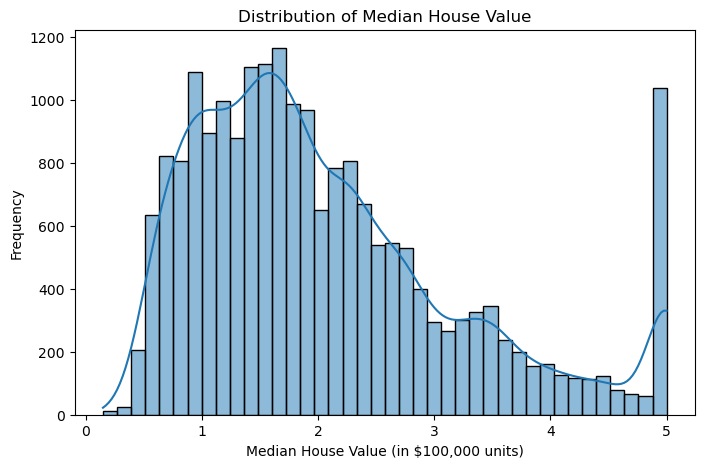

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df["MedHouseVal"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="MedHouseVal", bins=40, kde=True)

plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value (in $100,000 units)")
plt.ylabel("Frequency")
plt.show()

In [7]:
feature_columns = df.columns.drop("MedHouseVal")

df[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


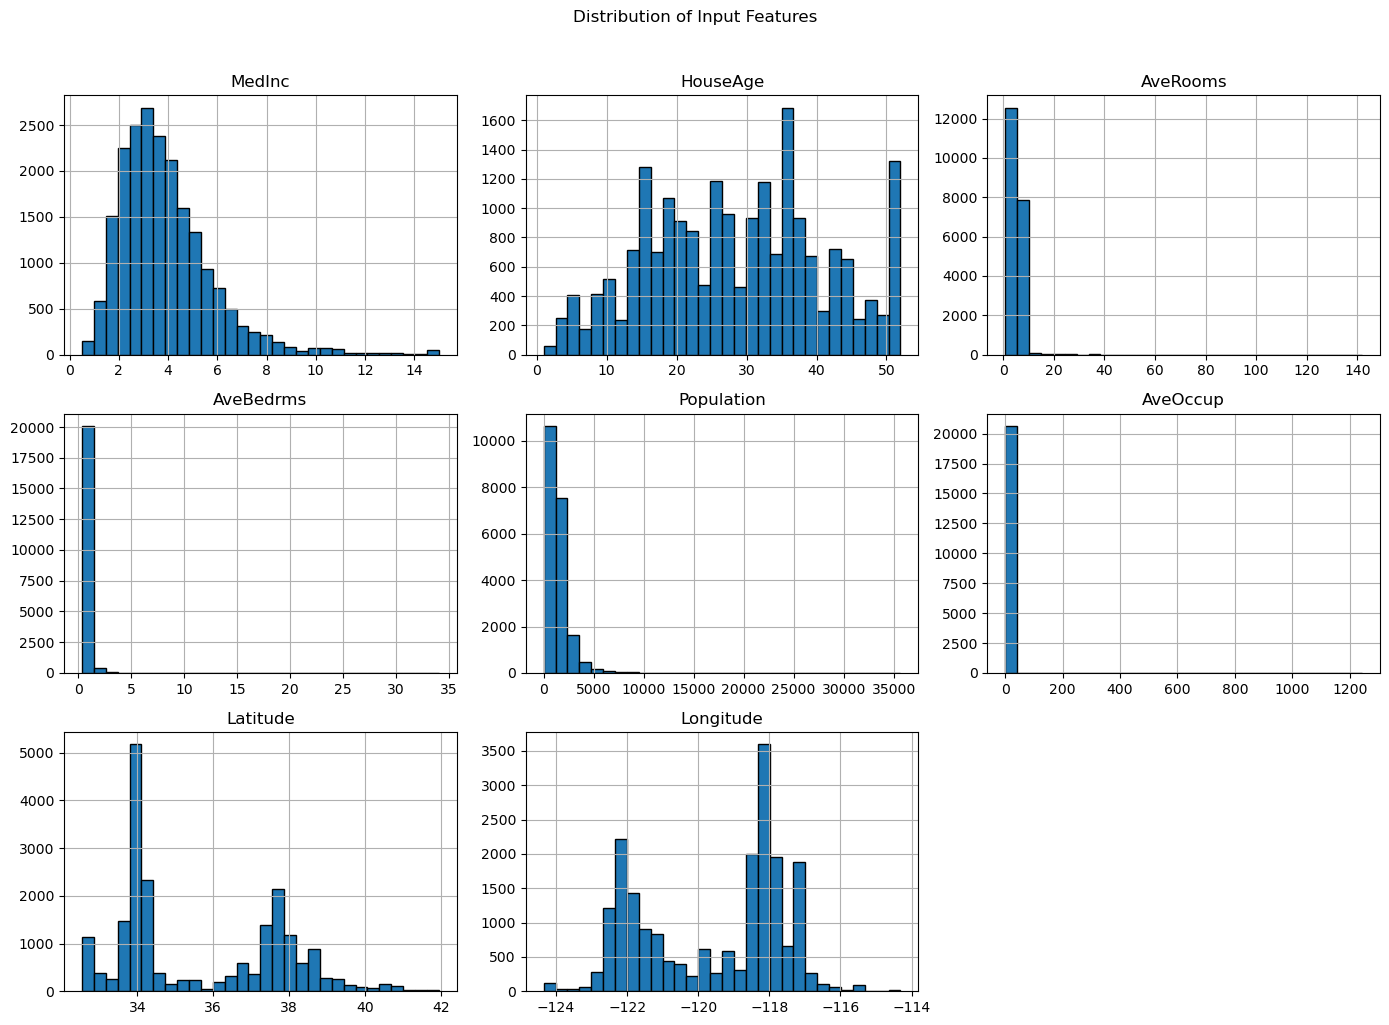

In [11]:
df[feature_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Input Features", y=1.02)
plt.tight_layout()
plt.show()

In [12]:
feature_columns = df.columns.drop("MedHouseVal")

feature_summary = df[feature_columns].describe().T

feature_summary["skewness"] = df[feature_columns].skew()

feature_summary[["min", "25%", "50%", "75%", "max", "skewness"]]

,min,25%,50%,75%,max,skewness
MedInc,0.499900,2.563400,3.534800,4.743250,15.000100,1.646657
HouseAge,1.000000,18.000000,29.000000,37.000000,52.000000,0.060331
AveRooms,0.846154,4.440716,5.229129,6.052381,141.909091,20.697869
AveBedrms,0.333333,1.006079,1.048780,1.099526,34.066667,31.316956
Population,3.000000,787.000000,1166.000000,1725.000000,35682.000000,4.935858
AveOccup,0.692308,2.429741,2.818116,3.282261,1243.333333,97.639561
Latitude,32.540000,33.930000,34.260000,37.710000,41.950000,0.465953
Longitude,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000,-0.297801


## 3. Correlation Analysis

Correlation measures the strength and direction of a linear relationship between two numerical variables.

We will use a correlation heatmap to examine:
- Relationships between input features
- Relationships between each feature and MedHouseVal
- Potential multicollinearity between input features

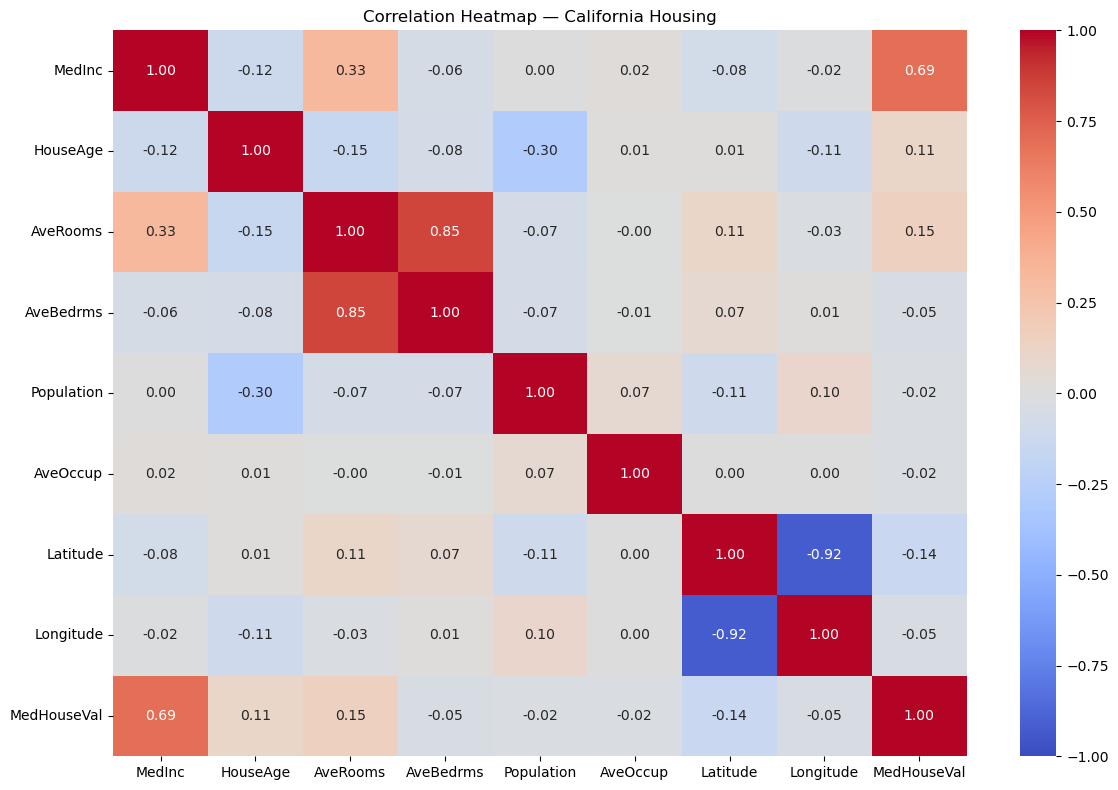

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap — California Housing")
plt.tight_layout()
plt.show()

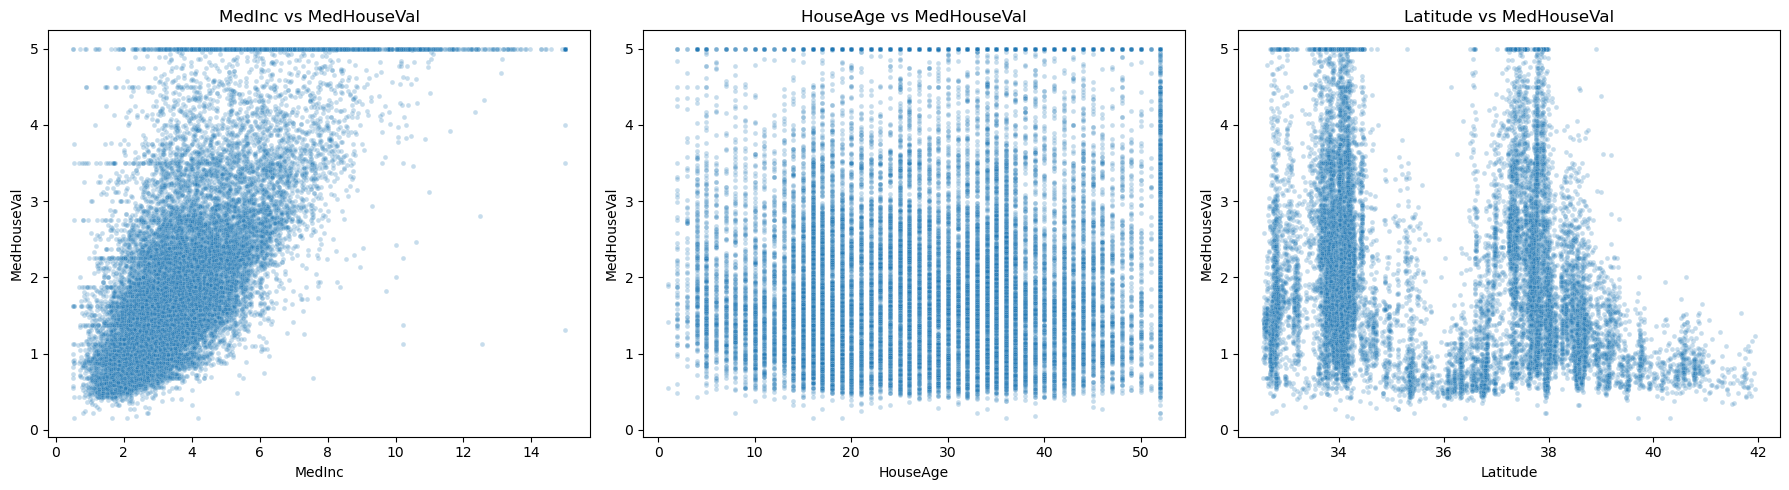

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features_to_plot = ["MedInc", "HouseAge", "Latitude"]

for ax, feature in zip(axes, features_to_plot):
    sns.scatterplot(
        data=df,
        x=feature,
        y="MedHouseVal",
        alpha=0.25,
        s=12,
        ax=ax
    )
    ax.set_title(f"{feature} vs MedHouseVal")

plt.tight_layout()
plt.show()

### EDA Findings: Feature–Target Relationships

1. **MedInc vs MedHouseVal:** A strong positive association is visible, although the points become more spread out at higher income levels.
2. **Target cap:** A horizontal band appears near MedHouseVal = 5, indicating that the target values are capped at the upper limit.
3. **Model implication:** The target cap may limit the model's ability to predict variation among the highest-value areas.

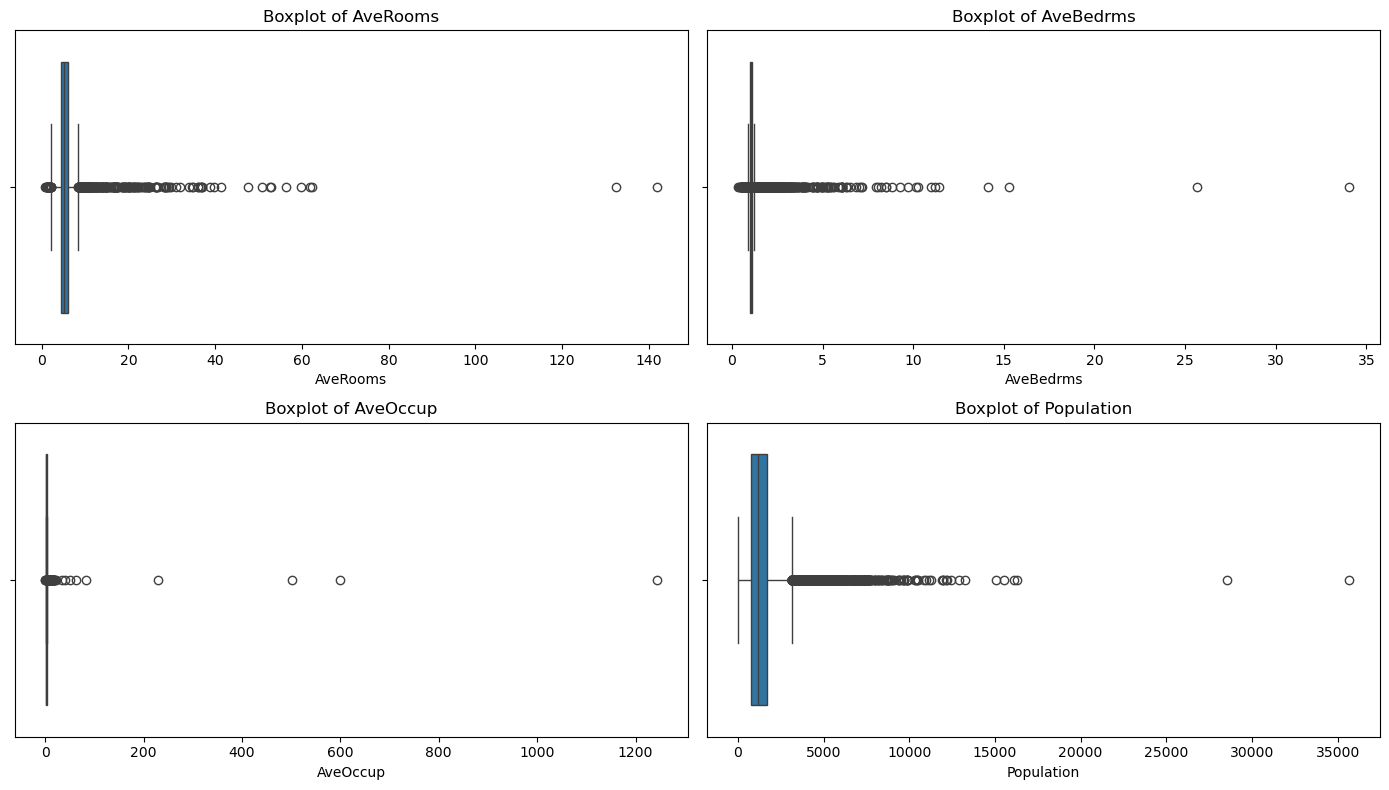

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

features_to_check = [
    "AveRooms",
    "AveBedrms",
    "AveOccup",
    "Population"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, feature in zip(axes.flat, features_to_check):
    sns.boxplot(x=df[feature], ax=ax)
    ax.set_title(f"Boxplot of {feature}")

plt.tight_layout()
plt.show()

In [16]:
features_to_check = [
    "AveRooms",
    "AveBedrms",
    "AveOccup",
    "Population"
]

for feature in features_to_check:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    print(f"\n{feature}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outlier count:", len(outliers))
    print("Largest values:")
    print(df[feature].nlargest(5).to_list())


AveRooms
Lower bound: 2.02
Upper bound: 8.47
Potential outlier count: 511
Largest values:
[141.9090909090909, 132.53333333333333, 62.422222222222224, 61.8125, 59.875]

AveBedrms
Lower bound: 0.87
Upper bound: 1.24
Potential outlier count: 1424
Largest values:
[34.06666666666667, 25.63636363636364, 15.3125, 14.11111111111111, 11.410714285714286]

AveOccup
Lower bound: 1.15
Upper bound: 4.56
Potential outlier count: 711
Largest values:
[1243.3333333333333, 599.7142857142857, 502.46153846153845, 230.17241379310343, 83.17142857142858]

Population
Lower bound: -620.0
Upper bound: 3132.0
Potential outlier count: 1196
Largest values:
[35682.0, 28566.0, 16305.0, 16122.0, 15507.0]


In [17]:
# Show the 5 most extreme observations for each feature
features_to_check = [
    "AveRooms",
    "AveBedrms",
    "AveOccup",
    "Population"
]

for feature in features_to_check:
    print(f"\n--- {feature} ---")

    display(
        df.nlargest(5, feature)[
            [
                "MedInc",
                "HouseAge",
                "AveRooms",
                "AveBedrms",
                "Population",
                "AveOccup",
                "Latitude",
                "Longitude",
                "MedHouseVal"
            ]
        ]
    )


--- AveRooms ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
1914,1.8750,33.0,141.909091,25.636364,30.0,2.727273,38.91,-120.10,5.00001
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500
12447,1.6154,17.0,62.422222,14.111111,83.0,1.844444,33.97,-114.49,0.87500
1913,4.0714,19.0,61.812500,11.000000,112.0,2.333333,39.01,-120.06,4.37500
11862,2.6250,25.0,59.875000,15.312500,28.0,1.750000,40.27,-121.25,0.67500



--- AveBedrms ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500
1914,1.8750,33.0,141.909091,25.636364,30.0,2.727273,38.91,-120.10,5.00001
11862,2.6250,25.0,59.875000,15.312500,28.0,1.750000,40.27,-121.25,0.67500
12447,1.6154,17.0,62.422222,14.111111,83.0,1.844444,33.97,-114.49,0.87500
9676,3.2431,14.0,52.848214,11.410714,265.0,2.366071,37.64,-119.02,2.21400



--- AveOccup ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
19006,10.2264,45.0,3.166667,0.833333,7460.0,1243.333333,38.32,-121.98,1.375
3364,5.5179,36.0,5.142857,1.142857,4198.0,599.714286,40.41,-120.51,0.675
16669,4.2639,46.0,9.076923,1.307692,6532.0,502.461538,35.32,-120.70,3.500
13034,6.1359,52.0,8.275862,1.517241,6675.0,230.172414,38.69,-121.15,2.250
9172,4.2391,5.0,5.123810,0.933333,8733.0,83.171429,34.47,-118.59,1.546



--- Population ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
15360,2.5729,14.0,5.270497,1.010484,35682.0,7.482072,33.35,-117.42,1.344
9880,2.3087,11.0,5.364518,1.059684,28566.0,4.696810,36.64,-121.79,1.188
13139,4.9516,3.0,7.338559,1.159015,16305.0,3.043113,38.43,-121.44,1.537
10309,7.4947,4.0,7.311043,1.054346,16122.0,3.106957,33.89,-117.74,3.663
6057,6.0191,8.0,6.347327,1.047525,15507.0,3.070693,34.03,-117.78,2.539


In [18]:
# Examine the distribution of AveOccup
print(df["AveOccup"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.995]
))

# Count observations above selected thresholds
for threshold in [10, 20, 50, 100]:
    count = (df["AveOccup"] > threshold).sum()
    print(f"AveOccup > {threshold}: {count} rows")

count    20640.000000
mean         3.070655
std         10.386050
min          0.692308
50%          2.818116
90%          3.885273
95%          4.333417
99%          5.394812
99.5%        6.122155
max       1243.333333
Name: AveOccup, dtype: float64
AveOccup > 10: 37 rows
AveOccup > 20: 10 rows
AveOccup > 50: 7 rows
AveOccup > 100: 4 rows


### AveOccup Outlier Analysis

- Median: 2.82
- 99th percentile: 5.39
- Maximum: 1243.33
- Values above 100: 4 rows

**Finding:** `AveOccup` is highly right-skewed, with a few extreme values.

**Decision:** Retain the feature for the initial model. Investigate the impact of extreme values during model evaluation.

In [21]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


### Define Features and Target

- `X`: 8 input features used to predict house value.
- `y`: `MedHouseVal`, the target variable.

The dataset contains 20,640 observations.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [23]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


### Train the Multiple Linear Regression Model

Created a `LinearRegression` model using Scikit-learn and trained it on `X_train` and `y_train`.

The model learns coefficients and an intercept from the training data.

In [24]:
# Predict house values using test features
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[0.477, 0.458, 5.00001, 2.186, 2.78, 1.587, 1.982, 1.575, 3.4, 4.466]

First 10 predicted values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


### Generate Predictions

Used `model.predict(X_test)` to predict house values for the test dataset.

- `y_test`: Actual house values.
- `y_pred`: Values predicted by the trained model.

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.533200130495655
MSE: 0.555891598695244
RMSE: 0.7455813830127761
R2 Score: 0.5757877060324511


### Initial Model Evaluation

- MAE: 0.5332 `(approximately $53,320)  `
- RMSE: 0.7456 `(approximately $74,558) ` 
- R²: 0.5758

**Finding:** The model explains approximately 57.6% of target variation on the test set. Further error analysis is needed before judging overall performance.

In [26]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison["Error"] = comparison["Actual"] - comparison["Predicted"]

comparison.head(10)

,Actual,Predicted,Error
20046,0.47700,0.719123,-0.242123
3024,0.45800,1.764017,-1.306017
15663,5.00001,2.709659,2.290351
20484,2.18600,2.838926,-0.652926
9814,2.78000,2.604657,0.175343
13311,1.58700,2.011754,-0.424754
7113,1.98200,2.645500,-0.663500
7668,1.57500,2.168755,-0.593755
18246,3.40000,2.740746,0.659254
5723,4.46600,3.915615,0.550385


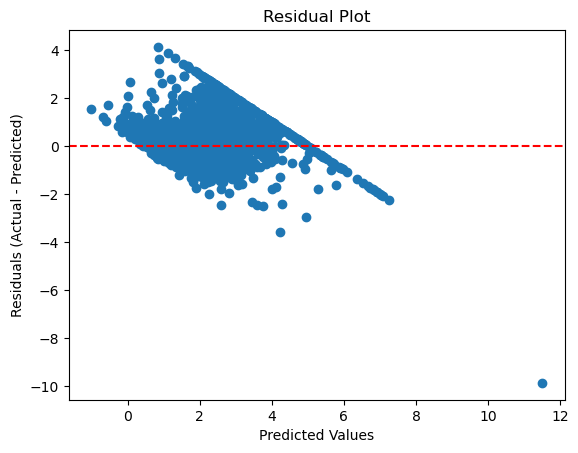

In [28]:
import matplotlib.pyplot as plt

plt.scatter(y_pred, y_test - y_pred)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

In [29]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison["Residual"] = comparison["Actual"] - comparison["Predicted"]

comparison.head(10)

,Actual,Predicted,Residual
20046,0.47700,0.719123,-0.242123
3024,0.45800,1.764017,-1.306017
15663,5.00001,2.709659,2.290351
20484,2.18600,2.838926,-0.652926
9814,2.78000,2.604657,0.175343
13311,1.58700,2.011754,-0.424754
7113,1.98200,2.645500,-0.663500
7668,1.57500,2.168755,-0.593755
18246,3.40000,2.740746,0.659254
5723,4.46600,3.915615,0.550385


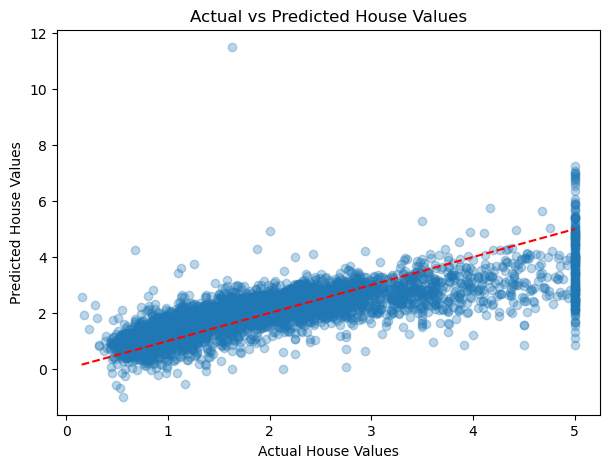

In [30]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")
plt.show()

### Actual vs Predicted Analysis

- Compared actual house values with model predictions.
- Residuals represent the difference between actual and predicted values.
- The residual plot shows no obvious curved pattern.
- Prediction errors still exist, so further model evaluation and improvement are needed.

In [31]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", round(baseline_mae, 4))
print("Linear Regression MAE:", round(mae, 4))

print("Baseline R²:", round(baseline_r2, 4))
print("Linear Regression R²:", round(r2, 4))

Baseline MAE: 0.9061
Linear Regression MAE: 0.5332
Baseline R²: -0.0002
Linear Regression R²: 0.5758


### Baseline Model Comparison

The Linear Regression model was compared with a Dummy Regressor
that predicts the mean target value.

- Baseline MAE: 0.9061
- Linear Regression MAE: 0.5332
- Baseline R²: -0.0002
- Linear Regression R²: 0.5758

Conclusion:
Linear Regression reduced MAE by approximately 41.2% compared
with the baseline. It also achieved a substantially higher R² score,
showing that the input features provide useful predictive information.
Further improvement may still be possible.

In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import numpy as np

def train_evaluate_model(model, X_train, X_test, y_train, y_test, scale=False):
    if scale:
        model = make_pipeline(StandardScaler(), model)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")

    return model, predictions

In [35]:
scaled_model, scaled_pred = train_evaluate_model(
    LinearRegression(),
    X_train, X_test,
    y_train, y_test,
    scale=True
)

MAE:  0.5332
RMSE: 0.7456
R²:   0.5758


In [36]:
from sklearn.linear_model import Ridge

ridge_model, ridge_pred = train_evaluate_model(
    Ridge(alpha=1.0),
    X_train, X_test,
    y_train, y_test,
    scale=True
)

MAE:  0.5332
RMSE: 0.7456
R²:   0.5758


In [37]:
for alpha in [0.1, 1, 10, 100]:
    print(f"\nRidge alpha = {alpha}")

    model, predictions = train_evaluate_model(
        Ridge(alpha=alpha),
        X_train, X_test,
        y_train, y_test,
        scale=True
    )


Ridge alpha = 0.1
MAE:  0.5332
RMSE: 0.7456
R²:   0.5758

Ridge alpha = 1
MAE:  0.5332
RMSE: 0.7456
R²:   0.5758

Ridge alpha = 10
MAE:  0.5331
RMSE: 0.7453
R²:   0.5761

Ridge alpha = 100
MAE:  0.5330
RMSE: 0.7438
R²:   0.5778


### Ridge Regression Comparison

Ridge Regression was evaluated with alpha values of 0.1, 1, 10, and 100.

The alpha=100 model achieved the lowest MAE (0.5330), lowest RMSE     
(0.7438), and highest R² (0.5778) among the tested settings.          

However, the improvement over the initial Linear Regression model        
was small. Therefore, alpha=100 is the best Ridge candidate among           
those tested, not necessarily the best possible model.            

In [38]:
from sklearn.linear_model import Lasso

lasso_model, lasso_pred = train_evaluate_model(
    Lasso(alpha=0.01, max_iter=10000),
    X_train, X_test,
    y_train, y_test,
    scale=True
)

MAE:  0.5353
RMSE: 0.7404
R²:   0.5816


In [39]:
from sklearn.linear_model import ElasticNet

elastic_model, elastic_pred = train_evaluate_model(
    ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000),
    X_train, X_test,
    y_train, y_test,
    scale=True
)

MAE:  0.5341
RMSE: 0.7416
R²:   0.5803


In [40]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge (alpha=100)",
        "Lasso (alpha=0.01)",
        "ElasticNet (alpha=0.01)"
    ],
    "MAE": [0.5332, 0.5330, 0.5353, 0.5341],
    "RMSE": [0.7456, 0.7438, 0.7404, 0.7416],
    "R2": [0.5758, 0.5778, 0.5816, 0.5803]
})

results.sort_values("R2", ascending=False)

,Model,MAE,RMSE,R2
2,Lasso (alpha=0.01),0.5353,0.7404,0.5816
3,ElasticNet (alpha=0.01),0.5341,0.7416,0.5803
1,Ridge (alpha=100),0.5330,0.7438,0.5778
0,Linear Regression,0.5332,0.7456,0.5758


In [41]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet

models = {
    "Ridge": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge())
        ]),
        {
            "model__alpha": [0.1, 1, 10, 100, 500]
        }
    ),
    "Lasso": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", Lasso(max_iter=20000))
        ]),
        {
            "model__alpha": [0.001, 0.01, 0.1, 1]
        }
    ),
    "ElasticNet": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", ElasticNet(max_iter=20000))
        ]),
        {
            "model__alpha": [0.001, 0.01, 0.1, 1],
            "model__l1_ratio": [0.2, 0.5, 0.8]
        }
    )
}

tuning_results = []
best_models = {}

for name, (pipeline, params) in models.items():
    search = GridSearchCV(
        pipeline,
        params,
        scoring="neg_mean_absolute_error",
        cv=5,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV MAE": -search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)
tuning_df.sort_values("Best CV MAE")

,Model,Best CV MAE,Best Parameters
0,Ridge,0.529023,{'model__alpha': 10}
2,ElasticNet,0.529032,"{'model__alpha': 0.001, 'model__l1_ratio': 0.2}"
1,Lasso,0.529121,{'model__alpha': 0.001}


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

final_comparison = []

for name, model in best_models.items():
    predictions = model.predict(X_test)

    final_comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

final_results = pd.DataFrame(final_comparison)
final_results.sort_values("MAE")

,Model,MAE,RMSE,R2
2,ElasticNet,0.533111,0.745083,0.576354
0,Ridge,0.533138,0.745342,0.576060
1,Lasso,0.533145,0.744642,0.576856


## Model Comparison and Selection

We evaluated three regularized regression models: Ridge, Lasso, and ElasticNet.

- **ElasticNet** achieved the lowest MAE of 0.533111.
- **Lasso** achieved the lowest RMSE of 0.744642 and the highest R² of 0.576856.
- **Ridge** achieved an MAE of 0.533138 and an R² of 0.576060.

The performance differences are very small. Based on the current test results, ElasticNet has the lowest MAE, while Lasso has the lowest RMSE and highest R².

We will consider the cross-validation results and our evaluation objective before selecting the final model.


In [46]:
# Select the model with the lowest cross-validation MAE
final_model = best_models["Ridge"]

final_predictions = final_model.predict(X_test)

In [47]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Final Model: Ridge Regression")
print(f"MAE:  {mean_absolute_error(y_test, final_predictions):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, final_predictions)):.4f}")
print(f"R²:   {r2_score(y_test, final_predictions):.4f}")

Final Model: Ridge Regression
MAE:  0.5331
RMSE: 0.7453
R²:   0.5761


The cross-validation results showed that Ridge achieved the lowest CV MAE of 0.529023, marginally outperforming ElasticNet and Lasso.

Therefore, Ridge Regression was selected as the final model based on its cross-validation performance. The differences between the three models were very small.

The selected Ridge model achieved a test MAE of 0.5331, RMSE of 0.7453, and R² of 0.5761.



## Final Conclusion

In this project, we built a House Price Prediction model using the California Housing dataset.

### Key Steps Completed
- Loaded and explored the dataset.
- Performed data cleaning and Exploratory Data Analysis (EDA).
- Analyzed feature distributions, correlations, and outliers.
- Split the data into training and testing sets.
- Trained and evaluated Linear Regression, Ridge, Lasso, and ElasticNet models.
- Used GridSearchCV with 5-fold cross-validation to tune regularization parameters.
- Compared model performance using MAE, RMSE, and R².

### Final Model: Ridge Regression

Ridge Regression was selected based on its lowest cross-validation MAE.

- **Test MAE:** 0.5331
- **Test RMSE:** 0.7453
- **Test R²:** 0.5761

The MAE corresponds to approximately $53,310 in the dataset's target units, because one target unit represents $100,000. The R² indicates that the model explains approximately 57.61% of the variation in the target values; it does not represent prediction accuracy.

### Limitations
- The model does not explain all the variation in house values.
- The target values in this dataset are capped at approximately $500,000.
- Predictions are estimates and should not be treated as exact market prices.

### Future Improvements
- Save the trained model for reuse.
- Build an interactive web interface using Streamlit.
- Deploy the application so users can try their own inputs.


In [48]:

import joblib

joblib.dump(final_model, "house_price_model.pkl")

print("Model saved successfully!")


Model saved successfully!
